# Analyse R-SIM Dataset, Preprocess #

In [1]:
import os
import sys
sys.path.append("/home/gavrilev/Thesis/src")

%load_ext autoreload
%autoreload 2
    
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

In [2]:
ALL_SFM_DATA = '/home/gavrilev/Thesis/src/datasets/RSIM/All_sf_dataset_v1.csv'
UNIQUE_RSIM_SMILES = '/home/gavrilev/Thesis/src/saved_objects/rsim_unique_smiles.pkl' # rsim unique smiles list
AUG_RSIM_SMILES = '/home/gavrilev/Thesis/src/saved_objects/rsim_aug_smiles.pkl' # augmented smiles list
SMILES2AUG_PATH = '/home/gavrilev/Thesis/src/saved_objects/smiles2aug.pkl' # dictionary that maps smiles -> smiles aug list 

In [3]:
def get_unique_smiles_rnas():
    all_sfm_df = pd.read_csv(ALL_SFM_DATA, delimiter='\t')
    unique_smiles, unique_rnas = set(list(all_sfm_df['SMILES'])), set(list(all_sfm_df['Target_RNA_sequence']))
    return unique_smiles, unique_rnas

def save_pkl(obj, path):
    with open(path, "wb") as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
def load_pkl(path):
    with open(path, "rb") as f:
        result = pickle.load(f)
    return result

In [5]:
all_sfm_df = pd.read_csv(ALL_SFM_DATA, delimiter='\t')
all_sfm_df.head()

,Entry_ID,SMILES,Target_RNA_sequence,Molecule_name,Molecule_ID,Target_RNA_name,Target_RNA_ID,pKd
0,2091,N[C@@H]1C[C@H](N)[C@H]([C@H]([C@H]1OCCCc1nnn(c...,CGCGCAGUCAGUAGCGCG,B-13,Target_lig_1138,RNA hairpin loop IV,Target_381,6.387216
1,162,C1CN(CCC1C(=O)NCCN2CCOCC2)CC3=CC=C(C=C3)Cl,GAGCGUCACACCUUCGGGUGAAGUCGCUC,1-(4-chlorobenzyl)-N-(2-morpholinoethyl)piperi...,Target_lig_132,A-site 16S rRNA_E_coli (1),Target_3,3.602060
2,270,c1c(ccc2Sc3ccccc3N(c12)CCCNCN(CO)CO)C(=O)C,GGCAGAUCUGAGCCUGGGAGCUCUCUGCC,3_phenothiazine_analog_1,Target_lig_210,HIV-1 TAR RNA,Target_19,2.522879
3,1327,C(CN1C=C(CNC2=C3C=CC=CC3=[NH+]C3=C2OC2=C3C=CC=...,GGGUUAGGGU,Quindoline CK1-14,Target_lig_723,TRF2:TERRA G-quadruplex (TERRA22):Telomeric du...,Target_262,6.272784
4,1907,C1=CC=C(C=C1)C2=NN=C(O2)C3=NC4=CC=CC=C4C(=N3)N...,UGUGGGAGGGGCGGGUCUGGG,NRAS SAR 7,Target_lig_1057,NRAS G4 motif,Target_259,6.443697


In [6]:
all_sfm_df.shape

(1439, 8)

<function matplotlib.pyplot.show(close=None, block=None)>

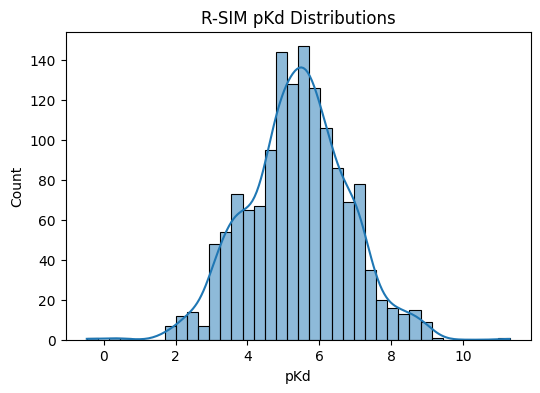

In [25]:
plt.figure(figsize=(6,4))
sns.histplot(data=all_sfm_df, x="pKd", kde=True)
plt.title('R-SIM pKd Distributions')
plt.show

## SMILES Enumeration as Data Augmentation

SMILES enumeration is a data augmentation technique in which multiple valid SMILES strings are generated for the same molecule by randomly changing the atom ordering before converting the molecule back to a SMILES representation. Since SMILES strings depend on the traversal order of atoms, different orderings produce different but chemically equivalent strings. 

This allows the model to observe multiple textual representations of the same molecule, improving robustness and reducing overfitting to a single canonical SMILES. During training, each RNA–molecule pair is therefore exposed with different randomized SMILES while keeping the RNA sequence and binding affinity label unchanged.

This approach follows the method proposed by Bjerrum (2017), where atom indices are randomly permuted and non-canonical SMILES are generated repeatedly to create unique augmented representations.

In [ ]:
from utils.utils import randomize_smiles, enumerate_unique
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

In [31]:
unique_smiles, unique_rna = set(list(all_sfm_df['SMILES'])), set(list(all_sfm_df['Target_RNA_sequence']))
print(f'Number of unique SMILES in R-SIM dataset -> {len(unique_smiles)}')
print(f'Number of unique RNAs in R-SIM dataset -> {len(unique_rna)}')

Number of unique SMILES in R-SIM dataset -> 759
Number of unique RNAs in R-SIM dataset -> 295


In [32]:
# save unique smiles
#save_pkl(obj=list(unique_smiles), path=UNIQUE_RSIM_SMILES)

In [33]:
longest_smiles = max(unique_smiles, key=len)
shortest_smiles = min(unique_smiles, key=len)

len(shortest_smiles), len(longest_smiles)

(15, 340)

In [34]:
smiles_lens = pd.DataFrame({'smi_len':[len(smi) for smi in unique_smiles]})

<function matplotlib.pyplot.show(close=None, block=None)>

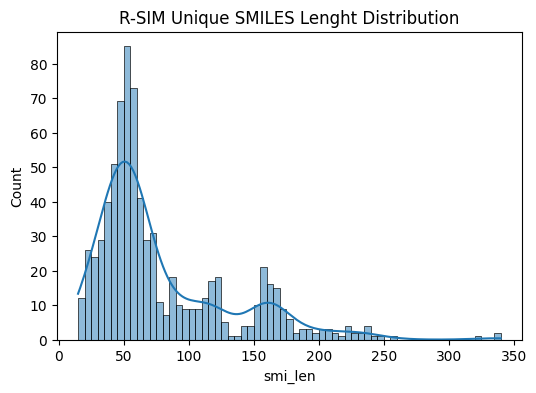

In [35]:
plt.figure(figsize=(6,4))
sns.histplot(data=smiles_lens, x="smi_len", binwidth=5, kde=True)
plt.title('R-SIM Unique SMILES Lenght Distribution')
plt.show

In [12]:
# test - A few SMILES strings will be enumerated as a demonstration
for i in range(10):
    print(randomize_smiles("CCC(=O)O[C@@]1(CC[NH+](C[C@H]1CC=C)C)c2ccccc2"))

c1([C@@]2(OC(CC)=O)CC[NH+](C)C[C@H]2CC=C)ccccc1
c1ccc([C@@]2(OC(=O)CC)CC[NH+](C)C[C@H]2CC=C)cc1
c1c([C@]2(OC(=O)CC)[C@H](CC=C)C[NH+](C)CC2)cccc1
C1[C@@](c2ccccc2)(OC(CC)=O)[C@H](CC=C)C[NH+](C)C1
c1cccc([C@]2(OC(CC)=O)[C@H](CC=C)C[NH+](C)CC2)c1
[C@@]1(OC(=O)CC)(c2ccccc2)CC[NH+](C)C[C@H]1CC=C
C1[C@@](c2ccccc2)(OC(=O)CC)[C@H](CC=C)C[NH+](C)C1
c1c([C@@]2(OC(=O)CC)CC[NH+](C)C[C@H]2CC=C)cccc1
c1([C@]2(OC(=O)CC)[C@H](CC=C)C[NH+](C)CC2)ccccc1
C1[C@@H](CC=C)[C@@](OC(=O)CC)(c2ccccc2)CC[NH+]1C


In [25]:
smiles2aug = {}
all_mols = []
N = 10
for smi in unique_smiles:
    curr_smiles = enumerate_unique(smiles=smi, n=N)
    all_mols.extend(curr_smiles)
    smiles2aug[smi] = curr_smiles

In [26]:
for k,v in smiles2aug.items():
    if len(v) != N:
        print(f'smi {k}, aug -> {len(v)}')

smi n1c(ncc(c1N)CN1=CC=CC(=C1)CCO[P@@](=O)(O)P(=O)(O)O)C, aug -> 1
smi c1c(cc2c(c1)[nH]c(n2)[C@H]1C[C@H](CCC1)N)N(=O)O, aug -> 1
smi [C@H]1([C@@H]([C@H](O)[C@H]([C@H](C1)N#N)O)OCc1ccc(cc1)c1ccc(cc1)CO[C@H]1[C@H](C[C@@H]([C@@H](O)[C@@H]1O)N#N)N#N)N#N, aug -> 1
smi [C@H]12[C@@H](C[C@@H]3[N@@](C1)(CCc1c3[nH]c3c1cccc3)C)[C@H]([C@H](CC2)O)C(=O)OC, aug -> 1
smi Ccc1nc2ccccc2cc1C(=O)O, aug -> 1
smi c1(c(cc2c(c1)nc(n2Cc1ccc(cc1N(=O)O)C(F)(F)F)C1CCNCC1)Cl)Cl, aug -> 1
smi Coc1ccc(cc1OCC1=NC2N(C1)C=CC=C2)NC(=O)CCCOc1ccc(cc1)c1[nH]c2c(n1)ccc(c2)c1ccc(cc1)N1CCN(CC1)C, aug -> 1
smi Coc1ccc2c(c1)c(Nc1ccc(c(c1)CN1CCN(CC1)C)O)c1c(n2)cc(cc1)Cl, aug -> 1
smi c1(c(cc2c(c1)nc(n2Cc1ccc(cc1N(=O)O)N(=O)O)C1CCNCC1)Cl)Cl, aug -> 1
smi Nc1nc(N)nc(n1)N, aug -> 4
smi Ccn1c2ccc(cc2c2c1cccc2)N1CCNCC1, aug -> 1


In [27]:
# save augmented smiles
#save_pkl(obj=all_mols, path=AUG_RSIM_SMILES)

In [28]:
len(all_mols), len(unique_smiles)

(7494, 759)

In [35]:
all_mols = load_pkl(AUG_RSIM_SMILES)

In [34]:
all_mols_ = []
for k, v in smiles2aug.items():
    all_mols_.extend(v)

In [37]:
all_mols_ == all_mols

True

In [29]:
shortest_smiles in smiles2aug[shortest_smiles]

True

In [30]:
random.choice(smiles2aug[longest_smiles]) # we are going to sample randomly to get different SMILES representation

'[nH]1c(-c2cc(C(C)(C)C)c(OCCCC(=O)CCCCn3nnc(CN(CC(=O)NCCCCNCCCNC(c4nc(-c5csc(CCNC(=O)C(NC(C(C(O)C(NC(=O)C(NC(=O)c6c(C)c(N)nc(C(NCC(N)C(N)=O)CC(=O)N)n6)C(OC6C(OC7OC(CO)C(O)C(OC(=O)N)C7O)C(O)C(O)C(CO)O6)c6[nH]cnc6)C)C)=O)C(C)O)n5)sc4)=O)C(N(CCC)CC(=O)N(C(CCCOc4ccc(-c5nc6c(ccc(N7CCN(C)CC7)c6)[nH]5)cc4)=O)CCC)=O)c3)c(C(C)(C)C)c2)nc2cc(N3CCN(C)CC3)ccc12'

In [31]:
#save_pkl(obj=smiles2aug, path=SMILES2AUG)

## Generate SMILES Embeddings for Augmentated Dataset ##

In [21]:
from utils.generate_smiles_features import *
from sklearn.metrics.pairwise import cosine_similarity

In [47]:
smiles_embedding_dict = generate_smiles_features(mol_set=all_mols, save=False, device='cpu')

1613


In [22]:
all_mols[:2]

['C(=O)([C@@H]1CCCN1C(=O)[C@@H](NC(c1c(CC)nc2cc3c(cccc3)cc2c1)=O)CCn1nnc(C[C@H](NC(=O)c2c(CC)nc3c(cc4c(c3)cccc4)c2)C(N2CCC[C@H]2C(=O)N[C@H](C(NCCC[NH3+])=O)Cc2ccccc2)=O)c1)N[C@H](C(=O)NCCC[NH3+])Cc1ccccc1',
 'CCC1=C(C=C2C=C3C=CC=CC3=CC2=N1)C(=O)N[C@@H](CCN1C=C(C[C@H](NC(=O)C2=C(CC)N=C3C=C4C=CC=CC4=CC3=C2)C(=O)N2CCC[C@H]2C(=O)N[C@@H](CC2=CC=CC=C2)C(=O)NCCC[NH3+])N=N1)C(=O)N1CCC[C@H]1C(=O)N[C@@H](CC1=CC=CC=C1)C(=O)NCCC[NH3+]']

In [ ]:
x = smiles_embedding_dict['chemberta'].iloc[0, 1:].to_numpy().reshape(1, -1)
y = smiles_embedding_dict['chemberta'].iloc[1, 1:].to_numpy().reshape(1, -1)

cosine_similarity(x, y)

In [91]:
smiles_embedding_dict['morgan fingerprints'].iloc[0,:] == smiles_embedding_dict['morgan fingerprints'].iloc[5,:]

SMILES           False
MorganFP_0        True
MorganFP_1        True
MorganFP_2        True
MorganFP_3        True
                 ...  
MorganFP_1019     True
MorganFP_1020     True
MorganFP_1021     True
MorganFP_1022     True
MorganFP_1023     True
Length: 1025, dtype: bool

In [120]:
chemberta_aug_dict = {'chemberta': smiles_embedding_dict['chemberta']}

In [122]:
chemberta_aug_dict['chemberta']

,SMILES,chemberta_feature_0,chemberta_feature_1,chemberta_feature_2,chemberta_feature_3,chemberta_feature_4,chemberta_feature_5,chemberta_feature_6,chemberta_feature_7,chemberta_feature_8,...,chemberta_feature_374,chemberta_feature_375,chemberta_feature_376,chemberta_feature_377,chemberta_feature_378,chemberta_feature_379,chemberta_feature_380,chemberta_feature_381,chemberta_feature_382,chemberta_feature_383
0,CCOC(=O)C1=CC=CC=C1NC(=O)N2CCCN(CC2)CC3=CSC(=N3)C,0.074891,-0.164561,-0.135672,0.241889,0.130150,0.200279,-0.109228,-0.088259,-0.117784,...,-0.107390,-0.018193,0.011991,-0.106029,0.246562,0.074247,0.239528,0.204077,0.074419,0.128548
1,CCOC(=O)c1ccccc1NC(N1CCN(Cc2nc(C)sc2)CCC1)=O,0.192871,-0.098423,-0.082731,0.082505,0.031848,0.046858,-0.141771,-0.077433,0.015387,...,0.133035,0.090344,0.006520,-0.010829,0.011982,0.061937,0.023896,-0.074362,0.064750,-0.095391
2,c1cc(C(=O)OCC)c(NC(N2CCCN(Cc3csc(C)n3)CC2)=O)cc1,0.162915,-0.010368,-0.085566,0.035190,-0.009742,0.147460,-0.108726,0.032165,-0.021383,...,0.146635,0.002644,0.007280,0.011258,-0.066295,0.063305,0.025139,-0.048692,-0.026246,-0.142074
3,c1(C)scc(CN2CCN(C(=O)Nc3c(C(OCC)=O)cccc3)CCC2)n1,-0.152295,0.311374,-0.117826,0.042319,-0.134997,0.218744,0.046141,-0.138815,0.000594,...,-0.034590,0.265011,0.016478,-0.170532,0.301785,0.184313,0.156797,0.166125,0.188242,0.170294
4,c1cccc(C(=O)OCC)c1NC(=O)N1CCCN(Cc2csc(C)n2)CC1,0.164220,0.068087,-0.126527,0.033975,0.033938,0.074476,-0.092234,-0.089755,-0.012842,...,0.007979,0.167859,0.002963,-0.129254,0.019659,-0.106253,0.246653,-0.072138,-0.014638,0.094437
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7489,n1c(OCCN(C)C)n(C)c2c(=O)n(C)c(=O)n(C)c12,-0.001944,0.096090,-0.107992,0.160971,0.159186,0.176398,0.054235,0.226539,0.054547,...,-0.169950,-0.214694,0.163200,0.193322,-0.005077,-0.033290,-0.051048,-0.015691,0.046148,0.040352
7490,c1(=O)c2c(n(C)c(=O)n1C)nc(OCCN(C)C)n2C,0.083549,-0.031763,-0.117582,0.121822,0.071524,0.239015,0.017603,0.288966,0.092365,...,-0.134473,-0.192256,0.178478,0.242104,0.086374,0.065507,-0.036504,-0.029070,0.151346,0.083458
7491,C(N(C)C)COc1nc2c(n1C)c(=O)n(C)c(=O)n2C,0.045925,-0.047357,-0.109853,0.202793,0.114826,0.139374,0.009095,0.221908,0.146065,...,-0.096577,-0.128440,0.191752,0.084957,0.017623,-0.084218,0.129784,-0.061834,0.121105,-0.180657
7492,CN1C2=C(N=C1OCCN(C)C)N(C(=O)N(C2=O)C)C,-0.292240,0.178113,-0.182466,0.387594,0.106694,0.312939,0.066503,0.117500,-0.206163,...,0.120554,-0.259006,0.230030,0.579105,0.290962,-0.155009,-0.263067,-0.099719,0.445673,0.044007


In [114]:
df = smiles_embedding_dict['mordred descriptors']
cols_1_or_2_unique = df.columns[df.nunique() <= 4]
cols_1_or_2_unique

Index(['nSpiro', 'nCl', 'nBr', 'nBondsT', 'NdCH2', 'NtsC', 'NsssNH', 'NddsN',
       'NssssN', 'NaaO', 'NssS', 'NddssS', 'NsCl', 'NsBr', 'StCH', 'SssNH2',
       'SssssN', 'SsI', 'MAXtCH', 'MAXssNH2', 'MAXtN', 'MAXsI', 'MINtCH',
       'MINssNH2', 'MINtN', 'MINsI', 'Lipinski', 'GhoseFilter', 'n7Ring',
       'nG12Ring', 'n7HRing', 'nG12HRing', 'n7ARing', 'nG12ARing', 'n7AHRing',
       'nG12AHRing', 'n8FRing', 'n10FRing', 'nG12FRing', 'n8FHRing',
       'n10FHRing', 'nG12FHRing', 'n10FaRing', 'nG12FaRing', 'n10FaHRing',
       'nG12FaHRing', 'nFARing', 'n8FARing', 'n9FARing', 'n10FARing',
       'nG12FARing', 'nFAHRing', 'n8FAHRing', 'n9FAHRing', 'n10FAHRing',
       'nG12FAHRing', 'SRW03'],
      dtype='object')

In [115]:
df.shape, df.drop(columns=cols_1_or_2_unique).shape

((7494, 1181), (7494, 1124))

In [145]:
SMILES_EMB_PATH = '/home/gavrilev/Thesis/src/embeddings/smiles/chemberta_aug.pkl'

In [146]:
with open(SMILES_EMB_PATH, "wb") as f:
    pickle.dump(smiles_embedding_dict, f, protocol=pickle.HIGHEST_PROTOCOL)

## SimSon Pre-Trained SMILES Sequence Embeddings ##

In [33]:
from utils.generate_smiles_features import extract_simson_embeddings

import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
import torch
import pickle

In [29]:
SIMSON_PT_WEIGHTS = "/home/gavrilev/Thesis/src/saved_objects/simson_pretrained_best_model.pth"
SIMSON_TOKENIZER_PATH = "/home/gavrilev/Thesis/src/saved_objects/pubchem_part_tokenizer.json"

ALL_SFM_DATA = '/home/gavrilev/Thesis/src/datasets/RSIM/All_sf_dataset_v1.csv'

In [37]:
unique_smiles, _ = get_unique_smiles_rnas()

In [30]:
SMILES2AUG_PATH = '/home/gavrilev/Thesis/src/saved_objects/smiles2aug.pkl'
with open(SMILES2AUG_PATH, "rb") as f:
    smiles2aug = pickle.load(f)

In [31]:
#smiles=smiles2aug['CCC1=C(C=C2C=C3C=CC=CC3=CC2=N1)C(=O)N[C@@H](CCN1C=C(C[C@H](NC(=O)C2=C(CC)N=C3C=C4C=CC=CC4=CC3=C2)C(=O)N2CCC[C@H]2C(=O)N[C@@H](CC2=CC=CC=C2)C(=O)NCCC[NH3+])N=N1)C(=O)N1CCC[C@H]1C(=O)N[C@@H](CC1=CC=CC=C1)C(=O)NCCC[NH3+]']
smiles=smiles2aug['C1=CC=NC(=C1)NCCN']

In [ ]:
# generate SimSon SMILES embeddings for unique SMILES in R-SIM dataset
embeddings = extract_simson_embeddings(unique_smiles)

In [ ]:
for i in range(len(embeddings)):
    for j in range(len(embeddings)):
        if i != j:
            cs_score = cosine_similarity(
                embeddings[i].cpu().numpy().reshape(1, -1),
                embeddings[j].cpu().numpy().reshape(1, -1)
            )
            print(f'cosine similarity score of {i} and {j} is -> {cs_score}')

## chemBERTa Pre-Trained SMILES Sequence Embedding ##

In [1]:
import sys
sys.path.append("/home/gavrilev/Thesis/src")

from utils.generate_smiles_features import *
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
SMILES2AUG_PATH = '/home/gavrilev/Thesis/src/saved_objects/smiles2aug.pkl'
with open(SMILES2AUG_PATH, "rb") as f:
    smiles2aug = pickle.load(f)

In [12]:
#smiles=smiles2aug['CCC1=C(C=C2C=C3C=CC=CC3=CC2=N1)C(=O)N[C@@H](CCN1C=C(C[C@H](NC(=O)C2=C(CC)N=C3C=C4C=CC=CC4=CC3=C2)C(=O)N2CCC[C@H]2C(=O)N[C@@H](CC2=CC=CC=C2)C(=O)NCCC[NH3+])N=N1)C(=O)N1CCC[C@H]1C(=O)N[C@@H](CC1=CC=CC=C1)C(=O)NCCC[NH3+]']
smiles=smiles2aug['C1=CC=NC(=C1)NCCN']

In [13]:
chemberta_model = ChemBERTaPT(smiles=smiles, batch_size = 32, device='cpu') # initialize pre-trained chemBERTa model (with custom changes)
chemberta_smiles_df = chemberta_model.batch_encode()

In [14]:
emb_list = [row.to_numpy(dtype=float) for _, row in chemberta_smiles_df.iloc[:, 1:].iterrows()]

In [ ]:
for i in range(len(emb_list)):
    for j in range(len(emb_list)):
        if i != j:
            cs_score = cosine_similarity(
                emb_list[i].reshape(1, -1),
                emb_list[j].reshape(1, -1)
            )
            print(f'cosine similarity score of {i} and {j} is -> {cs_score}')

In [7]:
res['chemberta']

,SMILES,chemberta_feature_0,chemberta_feature_1,chemberta_feature_2,chemberta_feature_3,chemberta_feature_4,chemberta_feature_5,chemberta_feature_6,chemberta_feature_7,chemberta_feature_8,...,chemberta_feature_374,chemberta_feature_375,chemberta_feature_376,chemberta_feature_377,chemberta_feature_378,chemberta_feature_379,chemberta_feature_380,chemberta_feature_381,chemberta_feature_382,chemberta_feature_383
0,C(CNCCCCNC(=O)CN(Cc1cn(CCCCC(CCCOc2c(C(C)(C)C)...,-1.269970,-0.749109,-0.679351,-0.191222,0.744283,-0.543174,-0.054611,-1.187608,-0.851395,...,0.456759,0.246534,-0.384364,0.129290,-1.259509,-0.212209,-0.417514,-0.277855,0.025306,0.082952
1,OC1C(OC2C(O)C(OC(=O)N)C(O)C(CO)O2)C(OC(C(NC(c2...,-1.641885,-0.359025,-0.621845,-0.128325,1.111883,-0.259255,0.000224,-1.081015,-0.669515,...,0.038996,-0.650098,-0.457663,0.555883,-0.829521,-0.598511,-1.464496,-0.478858,-0.085508,0.378701


In [9]:
x = res['chemberta'].iloc[0, 1:].to_numpy().reshape(1, -1)
y = res['chemberta'].iloc[1, 1:].to_numpy().reshape(1, -1)

In [10]:
cosine_similarity(x, y)

array([[0.78395889]])